# MLP–BG and GRU–BG: neural Bernoulli–Gamma baselines for probabilistic daily precipitation downscaling

## Notation

| Symbol | Meaning | In the code |
|---|---|---|
| $\mathbf{x}_t\in\mathbb{R}^m$ | large-scale predictors of day $t$ ($m=8$), standardized | `X_standardized` (numpy), `X_tensor` (torch) |
| $y_t$ | precipitation at the station on day $t$ (mm), with the amounts $\le\tau$ set to 0 | `y_all` (numpy), `y_tensor` (torch) |
| $\tau$ | wet-day threshold, 1 mm | `CFG.tau` |
| $\delta_t=\mathbf{1}\{y_t>\tau\}$ | wet-day indicator | `wet_all` |
| $\boldsymbol\eta_t=(\alpha_t,\mu_t,\pi_t)$ | Bernoulli–Gamma parameters: shape and mean of the Gamma distribution of the excess $y_t-\tau$, wet-day probability | `alpha`, `mu`, `wet_probability` |
| $\beta_t=\alpha_t/\mu_t$ | rate of the Gamma distribution of the excess | `beta` |
| $\mathbf{r}_t\in\mathbb{R}^{32}$ | representation of the predictors read by the output head: last hidden layer of MLP–BG, state of the GRU of GRU–BG | `context` |
| $\psi$ | parameters of MLP–BG or of GRU–BG | `model.parameters()` |
| $L$ | window of GRU–BG in training, 512 days | `CFG.window` |
| $N$ | ensemble members on each test day, 1000 | `CFG.ensemble_members` |

## 1. Setup

### 1.1 Environment and reproducibility

In [ ]:
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
os.environ["OMP_NUM_THREADS"] = "1"          # one intra-op thread, as --threads 1 of the script
os.environ["MKL_NUM_THREADS"] = "1"

import contextlib
import platform
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import torch
from IPython.display import display
from scipy.special import gammainc, gammaln, logsumexp
from scipy.stats import rankdata
from torch import nn
from torch.nn import functional as F

torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
pd.set_option("display.width", 160)

Python 3.10.19 | torch 2.11.0 | numpy 2.2.5 | pandas 2.3.3 | scipy 1.15.3 | macOS-27.2-arm64-arm-64bit | 8 cores


### 1.2 Configuration

In [2]:
class Config:
    def __init__(self):
        # Bernoulli–Gamma model specification
        self.tau = 1.0
        self.hidden_dim = 32
        self.head_hidden_dim = 32
        self.epsilon = 1e-6
        self.mlp_layers = 2
        self.gru_layers = 1

        # Fixed optimization and evaluation configuration
        self.batch_size = 256
        self.window = 512
        self.learning_rate = 1e-3
        self.weight_decay = 1e-4
        self.gradient_clip = 5.0
        self.max_epochs = 1000
        self.validation_every = 5
        self.patience = 10
        self.improvement_tolerance = 1e-3
        self.ensemble_members = 1000
        self.seed = 42

        # Architectures and temporal scales
        self.architectures = ("MLP_BG", "GRU_BG")
        self.time_scales = ("Annual", "SeasonalConcat", "MonthConcat")
        self.seasons = {"DJF": (12, 1, 2), "MAM": (3, 4, 5), "JJA": (6, 7, 8), "SON": (9, 10, 11)}
        self.predictors = ("d2m_mean", "t2m_mean", "msl_mean", "tcwv_mean", "u850_mean", "v850_mean", "z850_mean", "q850_mean")

        # Chronological data partition consistent with the DSSM experiment
        self.train_start = "1980-01-01"
        self.train_end = "2012-12-31"
        self.validation_start = "2013-01-01"
        self.validation_end = "2017-12-31"
        self.test_start = "2018-01-01"
        self.test_end = "2025-12-31"

        # Station, device and folders of the notebook: the root of the package holds data/ and results/
        self.station = "tours"
        self.device = torch.device("cpu")
        root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data" / "Data1Cell_06UTC").is_dir())
        self.era5_path = root / "data" / "Data1Cell_06UTC" / f"era5_daily_cell_{self.station}.npz"
        self.precipitation_path = root / "data" / "Data1Cell_06UTC" / f"ecad_rr_{self.station}_1980_2025.npy"
        self.output_dir = root / "results" / "notebook_mlp_gru_tours"

    def as_dict(self):
        return {k: (str(v) if isinstance(v, (Path, torch.device)) else v) for k, v in vars(self).items()}


CFG = Config()
CFG.output_dir.mkdir(parents=True, exist_ok=True)


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed % (2**32))
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


pd.Series({k: v for k, v in CFG.as_dict().items() if not k.endswith(("_path", "_dir"))}, dtype=object).to_frame("value")

,value
tau,1.0
hidden_dim,32
head_hidden_dim,32
epsilon,0.000001
mlp_layers,2
gru_layers,1
batch_size,256
window,512
learning_rate,0.001
weight_decay,0.0001


## 2. Problem and data

We observe a paired sequence $\{(\mathbf{x}_t,y_t)\}_{t=1}^{T}$ at one station:

- $\mathbf{x}_t\in\mathbb{R}^m$ holds the $m=8$ daily predictors of the ERA5 reanalysis (Hersbach et al., 2020) for
  the grid cell that contains the station;
- $y_t$ is the precipitation measured at the station on day $t$, from ECA&D (Klein Tank et al., 2002).

Amounts at or below the wet-day threshold $\tau=1$ mm are set to zero, so that $y_t\in\{0\}\cup(\tau,\infty)$, and
$\delta_t=\mathbf{1}\{y_t>\tau\}$ marks the wet days (Section 2.1 of the manuscript).

The two models are neural networks with the Bernoulli–Gamma output of DSSM–BG and without its latent state:

$$
\text{MLP–BG: }\ \boldsymbol\eta_t=\boldsymbol\eta_\psi(\mathbf{x}_t),\qquad
\text{GRU–BG: }\ \boldsymbol\eta_t=\boldsymbol\eta_\psi(\mathbf{x}_{1:t}),\qquad
p(y_t\mid\boldsymbol\eta_t)=\mathrm{BG}(y_t;\,\alpha_t,\mu_t,\pi_t).
$$

- **MLP–BG** is a **same-day model**, like GLM–BG and RF–BG: the parameters of day $t$ are functions of the predictors
  of that day only.
- **GRU–BG** has a **causal context**: the parameters of day $t$ depend on the predictors of that day and of all the
  preceding days, which the state of a forward recurrent network summarizes.

In both models, the predictive distribution of each day is one Bernoulli–Gamma distribution, and the members are drawn
independently from day to day. Neither model reads the observed precipitation as an input, so that no precipitation
of the target period is used.

**Splits.** The record is split in time and never shuffled.

| Period | Days | Use |
|---|---|---|
| 1980–2012 | 12 054 | training |
| 2013–2017 | 1826 | validation: selection of the checkpoint |
| 2018–2025 | 2922 | test: evaluation only |

**Scaling.** Each predictor is standardized with the mean and the standard deviation of 1980–2012, the training period
(`std` with `ddof=0`). The same transformation is applied to the validation and test days.

### 2.1 The station and the data

The eight predictors are ERA5 means over the 24 hours of the ECA&D observation day, from 06 UTC to 06 UTC.

In [3]:
with np.load(CFG.era5_path) as data:
    variable_names = data["variables"].astype(str).tolist()
    predictor_columns = [variable_names.index(name) for name in CFG.predictors]
    X_raw = data["data"][:, predictor_columns].astype(np.float64)
    dates = pd.DatetimeIndex(data["dates"].astype("datetime64[ns]"))

y_raw = np.load(CFG.precipitation_path).astype(np.float64)
y_all = np.where(y_raw <= CFG.tau, 0.0, y_raw)
months = dates.month.to_numpy()

train_rows = np.flatnonzero((dates >= CFG.train_start) & (dates <= CFG.train_end))
validation_rows = np.flatnonzero((dates >= CFG.validation_start) & (dates <= CFG.validation_end))
test_rows = np.flatnonzero((dates >= CFG.test_start) & (dates <= CFG.test_end))
history_rows = np.concatenate([train_rows, validation_rows])

x_mean = X_raw[train_rows].mean(axis=0)
x_std = X_raw[train_rows].std(axis=0, ddof=0)
x_std = np.where(x_std == 0.0, 1.0, x_std)
X_standardized = ((X_raw - x_mean) / x_std).astype(np.float32)
X_tensor = torch.tensor(X_standardized, dtype=torch.float32, device=CFG.device)
y_tensor = torch.tensor(y_all, dtype=torch.float32, device=CFG.device)
split_rows = {"train": train_rows, "validation": validation_rows, "test": test_rows}

wet_all = y_all > CFG.tau
assert len(y_all) == len(X_raw) and np.isfinite(X_raw).all() and np.isfinite(y_all).all()
assert (np.diff(dates.values) == np.timedelta64(1, "D")).all()

# The station (Table 1 of the manuscript) and the three periods
display(pd.DataFrame({"ECA&D identifier (STAID)": [2190], "latitude (°N)": [47.44], "longitude (°E)": [0.73], "elevation (m)": [108],
                      "mean annual precipitation (mm)": [round(pd.Series(y_raw).groupby(dates.year).sum().mean())],
                      "wet days (%)": [round(100 * wet_all.mean(), 1)]}, index=["Tours"]))
pd.DataFrame([{"split": name, "first": dates[rows[0]].date(), "last": dates[rows[-1]].date(), "days": len(rows),
               "wet days (%)": 100 * wet_all[rows].mean(), "mean wet-day amount (mm)": y_all[rows][wet_all[rows]].mean()}
              for name, rows in split_rows.items()]).set_index("split").round(2)

,ECA&D identifier (STAID),latitude (°N),longitude (°E),elevation (m),mean annual precipitation (mm),wet days (%)
Tours,2190,47.44,0.73,108,681,28.4


,first,last,days,wet days (%),mean wet-day amount (mm)
split,,,,,
train,1980-01-01,2012-12-31,12054,28.80,6.35
validation,2013-01-01,2017-12-31,1826,26.56,6.01
test,2018-01-01,2025-12-31,2922,28.10,6.16


### 2.2 Training scales and chains

Each model is trained at three training scales:

- **Annual** (`Annual`): one model, trained on all the days of the year;
- **Season** (`SeasonalConcat`): four models, one per season (DJF, MAM, JJA, SON), each trained on the days of its
  season;
- **Month** (`MonthConcat`): twelve models, one per calendar month.

`build_chains` returns, for a set of rows and a training scale, the rows of each group in calendar order: the
**chain** of the group. The model of a group is trained on its training chain, selected on its validation chain and
predicts its test chain, so that every test day is predicted by the model of its season or month. A finer scale lets
the relation between the predictors and the precipitation change through the year, but leaves fewer days to train
each model.

The order of the days does not matter for MLP–BG, which reads one day at a time. For GRU–BG, a chain is one sequence:
at the Season and Month scales, the days of a group are joined in calendar order, so that the state of the GRU passes
from the end of a season or month to the same season or month of the next year. The table gives the number of days of
each chain.

In [4]:
def build_chains(rows, time_scale):
    if time_scale == "Annual":
        return {"ALL": rows}
    if time_scale == "SeasonalConcat":
        groups = CFG.seasons
    else:
        groups = {f"{month:02d}": (month,) for month in range(1, 13)}
    return {group: rows[np.isin(months[rows], group_months)] for group, group_months in groups.items()}


pd.DataFrame([{"time_scale": time_scale, "group": group,
               **{f"{split} days": len(build_chains(rows, time_scale)[group]) for split, rows in split_rows.items()}}
              for time_scale in CFG.time_scales for group in build_chains(train_rows, time_scale)])

,time_scale,group,train days,validation days,test days
0,Annual,ALL,12054,1826,2922
1,SeasonalConcat,DJF,2979,451,722
2,SeasonalConcat,MAM,3036,460,736
3,SeasonalConcat,JJA,3036,460,736
4,SeasonalConcat,SON,3003,455,728
5,MonthConcat,01,1023,155,248
6,MonthConcat,02,933,141,226
7,MonthConcat,03,1023,155,248
8,MonthConcat,04,990,150,240
9,MonthConcat,05,1023,155,248


## 3. The Bernoulli–Gamma output of the two models

Both models predict, for each day, the three parameters of the Bernoulli–Gamma distribution of Eq. (1): the wet-day
probability $\pi_t$, and the shape $\alpha_t$ and the mean $\mu_t$ of the Gamma distribution of the excess $y_t-\tau$
on a wet day. The code also uses the rate $\beta_t=\alpha_t/\mu_t$:

$$
p(y_t\mid\boldsymbol\eta_t)=(1-\pi_t)^{1-\delta_t}\left[\pi_t\,\frac{\beta_t^{\alpha_t}}{\Gamma(\alpha_t)}\,
(y_t-\tau)^{\alpha_t-1}\,e^{-\beta_t(y_t-\tau)}\right]^{\delta_t},\qquad \beta_t=\frac{\alpha_t}{\mu_t}.
\tag{1}
$$

The two models differ only in the representation $\mathbf{r}_t$ of the predictors that they pass to an output head
$g_\psi$ of the same architecture, followed by the transformations:

$$
(\tilde\alpha_t,\tilde\mu_t,\tilde\pi_t)=g_\psi(\mathbf{r}_t),\qquad
\alpha_t=\epsilon+\operatorname{softplus}(\tilde\alpha_t),\quad
\mu_t=\epsilon+\operatorname{softplus}(\tilde\mu_t),\quad
\pi_t=\sigma(\tilde\pi_t).
$$

- **`BernoulliGammaHead`** is $g_\psi$: one hidden layer of 32 $\tanh$ units and three outputs, like the emission
  network of DSSM–BG. The softplus keeps $\alpha_t$ and $\mu_t$ positive, $\epsilon=10^{-6}$ keeps them away from zero,
  and the logistic function $\sigma$ maps $\tilde\pi_t$ to a probability. The head also returns the predictive mean
  $\mathbb{E}[y_t\mid\boldsymbol\eta_t]=\pi_t(\tau+\mu_t)$.
- **`bernoulli_gamma_log_prob`** evaluates $\log p(y_t\mid\boldsymbol\eta_t)$ from the logit of $\pi_t$, with
  $\log\sigma(\tilde\pi_t)$ and $\log\sigma(-\tilde\pi_t)$, which are numerically stable for any logit. On a dry day,
  the excess is replaced by 1, so that the Gamma term of the unused branch stays finite.
- **`negative_log_likelihood`** averages $-\log p(y_t\mid\boldsymbol\eta_t)$ over the days of a mini-batch or of a
  window: it is the training loss of both models.
- **`simulate_bernoulli_gamma`** draws the ensemble. Member $n$ of day $t$ is wet when a uniform draw falls below
  $\pi_t$, and its amount is then $\tau$ plus a Gamma draw with shape $\alpha_t$ and scale $1/\beta_t$. The members of a
  day are independent draws from the same distribution, and the draws of different days are independent too.

In [5]:
class BernoulliGammaHead(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.network = nn.Sequential(nn.Linear(input_dim, CFG.head_hidden_dim), nn.Tanh(), nn.Linear(CFG.head_hidden_dim, 3))

    def forward(self, context):
        wet_logit, raw_mu, raw_alpha = self.network(context).unbind(dim=-1)
        mu = CFG.epsilon + F.softplus(raw_mu)
        alpha = CFG.epsilon + F.softplus(raw_alpha)
        beta = alpha / mu
        wet_probability = torch.sigmoid(wet_logit)
        return {"wet_logit": wet_logit, "wet_probability": wet_probability, "mu": mu, "alpha": alpha, "beta": beta, "predicted_mean": wet_probability * (CFG.tau + mu)}


def bernoulli_gamma_log_prob(observed, wet_logit, alpha, beta):
    wet = observed > CFG.tau
    excess = torch.where(wet, observed - CFG.tau, torch.ones_like(observed))
    gamma_log_prob = alpha * torch.log(beta) - torch.lgamma(alpha) + (alpha - 1.0) * torch.log(excess) - beta * excess
    return torch.where(wet, F.logsigmoid(wet_logit) + gamma_log_prob, F.logsigmoid(-wet_logit))


def negative_log_likelihood(parameters, observed):
    return -bernoulli_gamma_log_prob(observed, parameters["wet_logit"], parameters["alpha"], parameters["beta"]).mean()


def simulate_bernoulli_gamma(parameters, members, rng):
    wet_probability = parameters["wet_probability"]
    alpha = parameters["alpha"]
    beta = parameters["beta"]
    wet = rng.random((len(wet_probability), members)) < wet_probability[:, None]
    excess = rng.gamma(shape=alpha[:, None], scale=1.0 / beta[:, None], size=(len(wet_probability), members))
    return np.where(wet, CFG.tau + excess, 0.0)

## 4. MLP–BG: multilayer perceptron

The Bernoulli–Gamma density network (Cannon, 2008) maps the predictors of the same day to the parameters through a
multilayer perceptron (Section 2.4 of the manuscript). Eq. (12) of the manuscript writes the whole network as
$g_\psi(\mathbf{x}_t)$; the code splits it into two hidden layers of 32 ReLU units (`encoder`) and the output head of
Section 3 (`head`):

$$
\mathbf{r}_t=\operatorname{ReLU}\bigl(W_2\operatorname{ReLU}(W_1\mathbf{x}_t+\mathbf{b}_1)+\mathbf{b}_2\bigr),\qquad
(\tilde\alpha_t,\tilde\mu_t,\tilde\pi_t)=g_\psi(\mathbf{r}_t).
\tag{12}
$$

- **Same day.** $\boldsymbol\eta_t$ depends on $\mathbf{x}_t$ only. The model has no memory, and the order of the
  training days does not matter.
- **Training** (`train_mlp_epoch`). Each epoch shuffles the training chain and cuts it into mini-batches of 256 days,
  with one AdamW step per mini-batch on the mean negative log-likelihood of the batch, and the gradient norm clipped
  at 5. The order comes from a generator of the chain, so that it does not depend on any other random draw. At the
  Annual scale, an epoch has 48 steps (12 054 days).
- **Loss of the epoch.** `train_mlp_epoch` returns the mean of the losses of the mini-batches, weighted by their
  numbers of days: the mean negative log-likelihood per day over the epoch, while the parameters change.

In [6]:
class MLPBG(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        layers = []
        current_dim = input_dim
        for _ in range(CFG.mlp_layers):
            layers.extend([nn.Linear(current_dim, CFG.hidden_dim), nn.ReLU()])
            current_dim = CFG.hidden_dim
        self.encoder = nn.Sequential(*layers)
        self.head = BernoulliGammaHead(CFG.hidden_dim)

    def forward(self, x):
        return self.head(self.encoder(x))


def tensor_rows(tensor, rows):
    return tensor[torch.as_tensor(rows, dtype=torch.long, device=tensor.device)]


def train_mlp_epoch(model, optimizer, rows, generator):
    model.train()
    order = torch.randperm(len(rows), generator=generator).numpy()
    total_loss = 0.0
    for start in range(0, len(rows), CFG.batch_size):
        batch_rows = rows[order[start:start + CFG.batch_size]]
        parameters = model(tensor_rows(X_tensor, batch_rows))
        loss = negative_log_likelihood(parameters, tensor_rows(y_tensor, batch_rows))
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), CFG.gradient_clip)
        optimizer.step()
        total_loss += float(loss.detach()) * len(batch_rows)
    return total_loss / len(rows)

## 5. GRU–BG: forward recurrent network

GRU–BG is the model of the ablation study with a causal context and without latent state (Appendix B of the
manuscript). A forward GRU with 32 units reads the predictors day by day, and its state $\mathbf{r}_t$ feeds the
output head of MLP–BG directly:

$$
\mathbf{r}_t=\mathrm{GRU}_\psi(\mathbf{x}_t,\mathbf{r}_{t-1}),\qquad
(\tilde\alpha_t,\tilde\mu_t,\tilde\pi_t)=g_\psi(\mathbf{r}_t).
\tag{B.1}
$$

One GRU step (Cho et al., 2014) with the input $\mathbf{x}_t$ and the previous state $\mathbf{r}_{t-1}$ is

$$
\begin{aligned}
\mathbf{g}^{\mathrm{r}}_t&=\sigma(W_{\mathrm{r}}\mathbf{x}_t+U_{\mathrm{r}}\mathbf{r}_{t-1}+\mathbf{b}_{\mathrm{r}}), &
\mathbf{g}^{\mathrm{u}}_t&=\sigma(W_{\mathrm{u}}\mathbf{x}_t+U_{\mathrm{u}}\mathbf{r}_{t-1}+\mathbf{b}_{\mathrm{u}}),\\
\mathbf{n}_t&=\tanh\bigl(W_{\mathrm{n}}\mathbf{x}_t+\mathbf{g}^{\mathrm{r}}_t\odot(U_{\mathrm{n}}\mathbf{r}_{t-1}+\mathbf{b}_{\mathrm{hn}})+\mathbf{b}_{\mathrm{n}}\bigr), &
\mathbf{r}_t&=(1-\mathbf{g}^{\mathrm{u}}_t)\odot\mathbf{n}_t+\mathbf{g}^{\mathrm{u}}_t\odot\mathbf{r}_{t-1}.
\end{aligned}
$$

The reset gate $\mathbf{g}^{\mathrm{r}}_t$ decides how much of the past enters the candidate $\mathbf{n}_t$, and the
update gate $\mathbf{g}^{\mathrm{u}}_t$ how much of the old state is kept, so that the state can keep information over
many days.

- **Causal context.** $\mathbf{r}_t$ depends on the predictors of day $t$ and of the preceding days,
  $\mathbf{x}_{1:t}$, and not on the following days. It is the context of the causal-context variant of DSSM–BG, with
  the same 32 units.
- **Training on windows** (`train_gru_epoch`). Each epoch runs the GRU over the training chain in consecutive windows
  of $L=512$ days, in chronological order, with one AdamW step per window on the mean negative log-likelihood of its
  days. The state starts from zero at the start of the epoch and is carried from one window to the next, but detached
  (`hidden.detach()`): the gradients stop at the window boundaries (truncated back-propagation through time), as for
  the particles of DSSM–BG. At the Annual scale, an epoch has 24 steps: 23 windows of 512 days and one of 278 days.
- **Filtering of the predictors before a target period** (`predict_parameters`, Section 6). To predict a validation or
  a test chain, the GRU first runs over the predictors of the chain that precedes it, in windows of 512 days from a
  zero state, and continues over the target chain from its last state: over 1980–2012 before the validation period,
  and over 1980–2017 before the test period. This step reads only predictors.
- **Season and Month scales.** A chain joins the days of its season or month in calendar order, so that the state of
  the GRU is carried across the gap between two years, for instance from the end of February to the next 1 December in
  the DJF chain.

In [7]:
class GRUBG(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.encoder = nn.GRU(input_dim, CFG.hidden_dim, num_layers=CFG.gru_layers, batch_first=True)
        self.head = BernoulliGammaHead(CFG.hidden_dim)

    def forward(self, x, hidden=None):
        context, hidden = self.encoder(x.unsqueeze(0), hidden)
        return self.head(context.squeeze(0)), hidden


def train_gru_epoch(model, optimizer, rows):
    model.train()
    hidden = None
    total_loss = 0.0
    for start in range(0, len(rows), CFG.window):
        chunk_rows = rows[start:start + CFG.window]
        parameters, hidden = model(tensor_rows(X_tensor, chunk_rows), hidden)
        loss = negative_log_likelihood(parameters, tensor_rows(y_tensor, chunk_rows))
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), CFG.gradient_clip)
        optimizer.step()
        hidden = hidden.detach()
        total_loss += float(loss.detach()) * len(chunk_rows)
    return total_loss / len(rows)

### 5.1 Size of the two models

Both models are small: they have the same output head, and the GRU has three times as many parameters as the two
hidden layers of the MLP. DSSM–BG, with its bidirectional context, its transition and emission networks and its
inference network, has 10 627 parameters.

In [8]:
sizes = {}
for label, example in (("MLP–BG", MLPBG(len(CFG.predictors))), ("GRU–BG", GRUBG(len(CFG.predictors)))):
    counts = {block: sum(p.numel() for name, p in example.named_parameters() if name.startswith(prefix))
              for block, prefix in (("hidden layers or GRU (encoder)", "encoder"), ("output head (head)", "head"))}
    counts["total"] = sum(counts.values())
    sizes[label] = counts
pd.DataFrame(sizes)

,MLP–BG,GRU–BG
hidden layers or GRU (encoder),1344,4032
output head (head),1155,1155
total,2499,5187


## 6. Training with model selection

### 6.1 Validation on the analytic CRPS

Every 5 epochs, the model predicts the Bernoulli–Gamma parameters of the validation chain, 2013–2017, and is scored
with the mean CRPS of these distributions. With $X$ and $X'$ independent draws from the predictive distribution $F_t$,
$\mathrm{CRPS}(F_t,y_t)=\mathbb{E}|X-y_t|-\frac12\mathbb{E}|X-X'|$, and for one Bernoulli–Gamma distribution both
expectations have a closed form. Let $G$ and $G'$ be independent excesses with shape
$\alpha_t$ and rate $\beta_t$, $m_t=\alpha_t/\beta_t$ their mean, $e_t=\max(y_t-\tau,0)$ the observed excess and
$P(a,x)$ the regularized lower incomplete gamma function (`gammainc`). Then

$$
\mathbb{E}|G-e_t|=e_t\bigl(2P(\alpha_t,\beta_te_t)-1\bigr)+m_t-2m_tP(\alpha_t+1,\beta_te_t),\qquad
\mathbb{E}|G-G'|=\frac{2\,\Gamma(\alpha_t+\frac12)}{\sqrt{\pi}\,\beta_t\,\Gamma(\alpha_t)},
$$

and, with half the expected distance between two draws $H_t=\frac12\mathbb{E}|X-X'|=\pi_t(1-\pi_t)(\tau+m_t)+\frac12\pi_t^2\,\mathbb{E}|G-G'|$,

$$
\mathrm{CRPS}(F_t,y_t)=\begin{cases}\pi_t(\tau+m_t)-H_t, & y_t=0,\\(1-\pi_t)\,y_t+\pi_t\,\mathbb{E}|G-e_t|-H_t, & y_t>\tau.\end{cases}
$$

`crps_bernoulli_gamma_analytic`, from `precipitation_metrics.py`, computes these terms.

- **No ensemble.** The validation needs no random draws. The fair CRPS of an ensemble drawn from the same distributions
  is an unbiased estimate of this value, so that the test scores of Section 7, which use the fair CRPS of the ensembles
  as for every model of the manuscript, are on the same scale.
- **GRU–BG.** The GRU first filters the predictors of the training chain, 1980–2012, and then predicts the validation
  chain from its last state, as it later predicts the test chain after 1980–2017 (`predict_parameters`).

### 6.2 The training loop

`train_chain` trains one chain:

- **Optimizer.** AdamW (Loshchilov and Hutter, 2019) with a learning rate of $10^{-3}$ and a weight decay of $10^{-4}$:
  one step per mini-batch for MLP–BG, and per window for GRU–BG.
- **Checkpoint.** A validation improves when its CRPS is lower than the best CRPS so far by more than $10^{-3}$. The
  model is then saved, and this CRPS becomes the best CRPS. A smaller decrease neither saves the model nor counts as an
  improvement, so that the kept epoch is the last one that improved by more than $10^{-3}$. (In the training of
  DSSM–BG, every decrease saves the model.)
- **Early stopping.** Training stops after 10 validations in a row without an improvement, or after 1000 epochs, and the
  saved model is reloaded.
- **Seeds.** `set_seed(42)` is called before the model is built, so that every chain starts from the same seed, and the
  mini-batch order of MLP–BG comes from its own generator, also seeded with 42.
- **Device.** The notebook trains on the CPU. The paper runs trained GRU–BG on the GPU, where cuDNN runs a window of
  512 days in one call; the floating-point results of the two devices differ in the last bits.

`model_folder` gives the folder of the checkpoints of a system, as in the script.

In [9]:
def threshold_precipitation(values, threshold=1.0):
    # Set precipitation at or below the wet-day threshold to zero.
    values = np.asarray(values, dtype=float)
    return np.where(values > threshold, values, 0.0)


def crps_bernoulli_gamma_analytic(observed, wet_probability, alpha, beta, threshold=1.0):
    # Daily analytic CRPS for 0 or threshold + Gamma(alpha, rate=beta).
    observed = threshold_precipitation(observed, threshold)
    wet_probability = np.clip(np.asarray(wet_probability, dtype=float), 0.0, 1.0)
    alpha = np.asarray(alpha, dtype=float)
    beta = np.asarray(beta, dtype=float)

    shifted_observed = np.maximum(observed - threshold, 0.0)
    gamma_mean = alpha / beta
    gamma_cdf = gammainc(alpha, beta * shifted_observed)
    truncated_first_moment = gamma_mean * gammainc(alpha + 1.0, beta * shifted_observed)
    expected_absolute_error = shifted_observed * (2.0 * gamma_cdf - 1.0) + gamma_mean - 2.0 * truncated_first_moment
    mean_absolute_gamma_difference = 2.0 * np.exp(gammaln(alpha + 0.5) - gammaln(alpha)) / (beta * np.sqrt(np.pi))
    half_expected_pair_distance = wet_probability * (1.0 - wet_probability) * (threshold + gamma_mean) + 0.5 * wet_probability**2 * mean_absolute_gamma_difference

    dry = observed == 0.0
    crps_dry = wet_probability * (threshold + gamma_mean) - half_expected_pair_distance
    crps_wet = (1.0 - wet_probability) * observed + wet_probability * expected_absolute_error - half_expected_pair_distance
    return np.where(dry, crps_dry, crps_wet)


def build_model(architecture):
    if architecture == "MLP_BG":
        return MLPBG(X_tensor.shape[1]).to(CFG.device)
    return GRUBG(X_tensor.shape[1]).to(CFG.device)


@torch.inference_mode()
def predict_parameters(architecture, model, filter_rows, target_rows):
    model.eval()
    if architecture == "MLP_BG":
        parameters = model(tensor_rows(X_tensor, target_rows))
    else:
        hidden = None
        for start in range(0, len(filter_rows), CFG.window):
            _, hidden = model(tensor_rows(X_tensor, filter_rows[start:start + CFG.window]), hidden)
        parameters, _ = model(tensor_rows(X_tensor, target_rows), hidden)
    return {name: values.detach().cpu().numpy().astype(np.float64) for name, values in parameters.items() if name != "wet_logit"}


def validation_crps(architecture, model, training_chain, validation_chain):
    parameters = predict_parameters(architecture, model, training_chain, validation_chain)
    return float(crps_bernoulli_gamma_analytic(y_all[validation_chain], parameters["wet_probability"], parameters["alpha"], parameters["beta"], CFG.tau).mean())


def train_chain(architecture, training_chain, validation_chain, seed, checkpoint_path, metadata):
    set_seed(seed)
    model = build_model(architecture)
    optimizer = torch.optim.AdamW(model.parameters(), lr=CFG.learning_rate, weight_decay=CFG.weight_decay)
    generator = torch.Generator().manual_seed(seed)
    best_crps = float("inf")
    bad_checks = 0
    history = []

    for epoch in range(1, CFG.max_epochs + 1):
        if architecture == "MLP_BG":
            train_nll = train_mlp_epoch(model, optimizer, training_chain, generator)
        else:
            train_nll = train_gru_epoch(model, optimizer, training_chain)
        current_crps = np.nan

        if epoch % CFG.validation_every == 0 or epoch == CFG.max_epochs:
            current_crps = validation_crps(architecture, model, training_chain, validation_chain)
            if current_crps < best_crps - CFG.improvement_tolerance:
                best_crps = current_crps
                bad_checks = 0
                checkpoint = {"state_dict": {name: value.detach().cpu().clone() for name, value in model.state_dict().items()}, "epoch": epoch, "validation_crps": current_crps, "seed": seed, "settings": CFG.as_dict(), "metadata": metadata}
                torch.save(checkpoint, checkpoint_path)
            else:
                bad_checks += 1
            print(f"{metadata['model']}/{metadata['group']} | epoch {epoch} | NLL {train_nll:.4f} | validation CRPS {current_crps:.4f}", flush=True)

        history.append({"epoch": epoch, "train_nll": train_nll, "validation_crps": current_crps})
        if bad_checks >= CFG.patience:
            break

    checkpoint = torch.load(checkpoint_path, map_location=CFG.device, weights_only=True)
    model.load_state_dict(checkpoint["state_dict"])
    model.eval()
    model.requires_grad_(False)
    return model, pd.DataFrame(history), checkpoint


def model_folder(architecture, time_scale):
    folder = CFG.output_dir / f"{architecture}_{time_scale}" / f"seed{CFG.seed}"
    folder.mkdir(parents=True, exist_ok=True)
    return folder

### 6.3 Fitting the six systems

The loop trains the 34 chains: MLP–BG and GRU–BG at the three training scales,
one chain per group, each saved where `run_one_chain` of the script saves it. Each trained chain then predicts the
Bernoulli–Gamma parameters of its test chain, after the GRU of GRU–BG has filtered the predictors of the history chain
of the group (1980–2017), and the parameters of the groups are assembled into one series of test days per system, as
`assemble` does in the script. `train_chain` prints one line per validation; these lines go to one log file per chain,
in `logs/`. The chain log gives, for each chain, its numbers of days, the number of epochs trained, the kept epoch, its
validation CRPS and the time of the chain.

In [10]:
parameters_by_model = {}
training_tables, chain_log_rows = [], []
(CFG.output_dir / "logs").mkdir(exist_ok=True)
for architecture in CFG.architectures:
    for time_scale in CFG.time_scales:
        model_name = f"{architecture}_{time_scale}"
        folder = model_folder(architecture, time_scale)
        training_chains = build_chains(train_rows, time_scale)
        validation_chains = build_chains(validation_rows, time_scale)
        history_chains = build_chains(history_rows, time_scale)
        test_chains = build_chains(test_rows, time_scale)
        combined = {}
        started_model = time.perf_counter()

        for group in training_chains:
            started = time.perf_counter()
            metadata = {"model": model_name, "architecture": architecture, "time_scale": time_scale, "group": group}
            with open(CFG.output_dir / "logs" / f"{model_name}_{group}.log", "w") as log_file, contextlib.redirect_stdout(log_file):
                model, training_log, checkpoint = train_chain(architecture, training_chains[group], validation_chains[group], CFG.seed, folder / f"{group}.pt", metadata)
            training_log.insert(0, "group", group)
            training_log.insert(0, "model", model_name)
            training_tables.append(training_log)

            parameters = predict_parameters(architecture, model, history_chains[group], test_chains[group])
            calendar_positions = np.searchsorted(test_rows, test_chains[group])
            for name, values in parameters.items():
                if name not in combined:
                    combined[name] = np.empty(len(test_rows), dtype=np.float64)
                combined[name][calendar_positions] = values
            chain_log_rows.append({"model": model_name, "group": group, "train_days": len(training_chains[group]),
                                   "validation_days": len(validation_chains[group]), "history_days": len(history_chains[group]),
                                   "test_days": len(test_chains[group]), "epochs": len(training_log), "selected_epoch": checkpoint["epoch"],
                                   "validation_crps": checkpoint["validation_crps"], "seconds": round(time.perf_counter() - started, 1)})
            del model
        parameters_by_model[model_name] = combined
        print(f"{model_name:<22s} {len(training_chains):2d} chains trained in {time.perf_counter() - started_model:5.0f} s", flush=True)

# Outputs: the training history, the chain log and the parameters of the test days
training_history = pd.concat(training_tables, ignore_index=True)
chain_log = pd.DataFrame(chain_log_rows)
training_history.to_csv(CFG.output_dir / "training_history.csv", index=False)
chain_log.to_csv(CFG.output_dir / "chain_log.csv", index=False)
pd.DataFrame({"date": dates[test_rows].date, **{f"{model_name}_{name}": parameters[name] for model_name, parameters in parameters_by_model.items()
                                                 for name in ("wet_probability", "alpha", "mu", "beta")}}).to_csv(CFG.output_dir / "test_parameters.csv", index=False)
chain_log.groupby("model", sort=False).agg(chains=("group", "size"), epochs=("epochs", "sum"), kept_epoch_min=("selected_epoch", "min"),
                                           kept_epoch_max=("selected_epoch", "max"), seconds=("seconds", "sum"))

MLP_BG_Annual           1 chains trained in     9 s
MLP_BG_SeasonalConcat   4 chains trained in     8 s
MLP_BG_MonthConcat     12 chains trained in     9 s
GRU_BG_Annual           1 chains trained in   201 s
GRU_BG_SeasonalConcat   4 chains trained in   251 s
GRU_BG_MonthConcat     12 chains trained in   299 s


,chains,epochs,kept_epoch_min,kept_epoch_max,seconds
model,,,,,
MLP_BG_Annual,1,205,155,155,8.7
MLP_BG_SeasonalConcat,4,815,95,225,7.5
MLP_BG_MonthConcat,12,2720,105,290,8.6
GRU_BG_Annual,1,170,120,120,200.7
GRU_BG_SeasonalConcat,4,880,160,190,250.8
GRU_BG_MonthConcat,12,3305,110,350,299.1


### 6.4 Training curves of the Annual chains

The training history of a chain records the loss of every epoch (Section 4) and the validation CRPS of every fifth
epoch.

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(10.5, 5.4), dpi=110, sharex="col", sharey="row")
for column, architecture in enumerate(CFG.architectures):
    model_name = f"{architecture}_Annual"
    log = training_history[training_history.model == model_name]
    valid = log.dropna(subset=["validation_crps"])
    kept = chain_log.set_index("model").loc[model_name]
    label = architecture.replace("_", "–")
    axes[0, column].plot(log.epoch, log.train_nll, color="#1a1a1a", lw=1.2)
    axes[1, column].plot(valid.epoch, valid.validation_crps, "-o", color="#1a1a1a", lw=1.2, ms=3)
    for ax in axes[:, column]:
        ax.axvline(kept.selected_epoch, color="0.45", ls=":", lw=0.9)
    axes[1, column].annotate(f"kept: epoch {kept.selected_epoch}", (kept.selected_epoch, kept.validation_crps), xytext=(12, 28),
                             textcoords="offset points", fontsize=8, arrowprops={"arrowstyle": "-", "color": "0.45", "lw": 0.8})
    axes[0, column].set_title(f"({'ab'[column]}) {label}: loss per day of the training chain", loc="left", fontsize=10)
    axes[1, column].set_title(f"({'cd'[column]}) {label}: validation CRPS, 2013–2017", loc="left", fontsize=10)
    axes[1, column].set_xlabel("epoch")
axes[0, 0].set(ylabel="negative log-likelihood", ylim=(0.95, 1.25))      # the losses of the first epochs lie above
axes[1, 0].set_ylabel("mm day$^{-1}$")
fig.tight_layout()
plt.show()
chain_log[chain_log.group == "ALL"].set_index("model")[["epochs", "selected_epoch", "validation_crps", "seconds"]].round(4)

**Figure 1.** Training of the Annual chains of MLP–BG and GRU–BG. (a, b) Loss of every epoch: mean negative
log-likelihood per day of the training chain 1980–2012. (c, d) Analytic CRPS of the validation period 2013–2017, every 5 epochs. The dotted line marks the kept epoch.

## 7. Ensembles and evaluation on the test period 2018–2025

### 7.1 Ensembles

As `assemble` of the script, the notebook draws the 1000 members of each test day with `simulate_bernoulli_gamma`, from
one generator, `default_rng(42)`, in a fixed order: MLP–BG then GRU–BG, Annual then Season then Month, and the groups
in calendar order, with one call of `simulate_bernoulli_gamma` per group. With the same parameters, the notebook therefore draws the same members as the
paper run. The members are kept as 64-bit numbers, as in the files `test_ensemble.npz` of the paper runs.

In [12]:
ensembles = {}
ensemble_rng = np.random.default_rng(CFG.seed)
for architecture in CFG.architectures:
    for time_scale in CFG.time_scales:
        model_name = f"{architecture}_{time_scale}"
        rainfall = np.empty((len(test_rows), CFG.ensemble_members), dtype=np.float64)
        for group, test_chain in build_chains(test_rows, time_scale).items():
            calendar_positions = np.searchsorted(test_rows, test_chain)
            group_parameters = {name: values[calendar_positions] for name, values in parameters_by_model[model_name].items()}
            rainfall[calendar_positions] = simulate_bernoulli_gamma(group_parameters, CFG.ensemble_members, ensemble_rng)
        ensembles[model_name] = rainfall
observed = y_all[test_rows]
test_dates = dates[test_rows]
pd.DataFrame([{"model": model_name, "days": ensemble.shape[0], "members": ensemble.shape[1], "wet members (%)": round(100 * (ensemble > CFG.tau).mean(), 1),
               "observed wet days (%)": round(100 * (observed > CFG.tau).mean(), 1)} for model_name, ensemble in ensembles.items()]).set_index("model")

,days,members,wet members (%),observed wet days (%)
model,,,,
MLP_BG_Annual,2922,1000,27.8,28.1
MLP_BG_SeasonalConcat,2922,1000,27.6,28.1
MLP_BG_MonthConcat,2922,1000,28.1,28.1
GRU_BG_Annual,2922,1000,29.7,28.1
GRU_BG_SeasonalConcat,2922,1000,28.6,28.1
GRU_BG_MonthConcat,2922,1000,29.3,28.1


### 7.2 Scores

Let $\mathcal{T}$ be the 2922 test days, $y_t$ the observation and $y^{(1)}_t,\ldots,y^{(N)}_t$ the members of day $t$. The scores are proper scoring rules or measures of discrimination (Gneiting and
Raftery, 2007):

- **CRPS**, from the ensemble with the fair estimator (Ferro, 2014), and, for
  comparison, from the Bernoulli–Gamma distribution in closed form (Section 6.1), averaged over $\mathcal{T}$, in
  mm day$^{-1}$;
- **NLL**: $-\frac{1}{|\mathcal{T}|}\sum_t\log p(y_t\mid\boldsymbol\eta_t)$;
- **Brier score** and **AUC** of the wet-day probability $\pi_t$;
- **COR** and **RMSE** of the ensemble mean;
- **CRPSS** of the fair CRPS against the monthly climatology of Eq. (A.7), whose 1000 members are drawn from
  the days of the same calendar month in 1980–2017.

The functions below are those of `precipitation_metrics.py`, which the script uses. The climatology is drawn with the
generator of numpy as in `stations_summary.py`, so that it is the climatology of the manuscript.

In [ ]:
def wet_day(values, threshold=1.0):
    # Wet indicator using the strict definition precipitation > threshold.
    return np.asarray(values, dtype=float) > threshold


def crps_ensemble_fair(observed, ensemble, threshold=1.0):
    # Daily fair ensemble CRPS; ensemble shape is (time, member).
    observed = threshold_precipitation(observed, threshold)
    ensemble = threshold_precipitation(ensemble, threshold)
    n_members = ensemble.shape[1]
    if n_members < 2:
        return np.full(observed.shape, np.nan, dtype=float)

    first_term = np.mean(np.abs(ensemble - observed[:, None]), axis=1)
    ordered = np.sort(ensemble, axis=1)
    coefficients = 2.0 * np.arange(1, n_members + 1) - n_members - 1.0
    pairwise_sum = np.sum(ordered * coefficients[None, :], axis=1)
    correction = pairwise_sum / (n_members * (n_members - 1.0))
    return first_term - correction


def bernoulli_gamma_log_likelihood(observed, wet_probability, alpha, beta, threshold=1.0):
    # Daily log predictive density of 0 or threshold + Gamma(alpha, rate=beta). With 2-d parameters (time, member),
    # the predictive is the equal-weight mixture of the members, closed with logsumexp over the members.
    observed = threshold_precipitation(observed, threshold)
    wet_probability = np.clip(np.asarray(wet_probability, dtype=float), 1e-12, 1.0 - 1e-12)
    alpha = np.asarray(alpha, dtype=float)
    beta = np.asarray(beta, dtype=float)

    mixture = wet_probability.ndim == 2
    wet = observed > 0.0
    excess = np.maximum(observed - threshold, 1e-12)
    if mixture:
        wet, excess = wet[:, None], excess[:, None]

    log_wet = (np.log(wet_probability) + alpha * np.log(beta) - gammaln(alpha)
               + (alpha - 1.0) * np.log(excess) - beta * excess)
    log_density = np.where(wet, log_wet, np.log1p(-wet_probability))
    if not mixture:
        return log_density
    return logsumexp(log_density, axis=1) - np.log(log_density.shape[1])


def brier_score(observed, wet_probability, threshold=1.0):
    # Brier score for the event precipitation > threshold.
    target = wet_day(observed, threshold).astype(float)
    probability = np.clip(np.asarray(wet_probability, dtype=float), 0.0, 1.0)
    return float(np.mean((probability - target) ** 2))


def auc_score(observed, wet_probability, threshold=1.0):
    # ROC AUC for wet occurrence, computed from ranks.
    target = wet_day(observed, threshold).astype(int)
    probability = np.asarray(wet_probability, dtype=float)
    n_wet = int(np.sum(target == 1))
    n_dry = int(np.sum(target == 0))
    if n_wet == 0 or n_dry == 0:
        return np.nan
    ranks = rankdata(probability, method="average")
    rank_sum_wet = np.sum(ranks[target == 1])
    return float((rank_sum_wet - n_wet * (n_wet + 1) / 2) / (n_wet * n_dry))


def root_mean_squared_error(observed, predicted):
    # sqrt(mean((prediction - observation)^2)).
    difference = np.asarray(predicted, dtype=float) - np.asarray(observed, dtype=float)
    return float(np.sqrt(np.mean(np.square(difference))))


def pearson_correlation(observed, predicted):
    # Pearson correlation over finite pairs; NaN when it is undefined rather than an error.
    observed = np.asarray(observed, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    valid = np.isfinite(observed) & np.isfinite(predicted)
    if valid.sum() < 2:
        return np.nan
    observed, predicted = observed[valid], predicted[valid]
    if np.std(observed) == 0.0 or np.std(predicted) == 0.0:
        return np.nan
    return float(np.corrcoef(observed, predicted)[0, 1])


def climatology_ensemble():
    # Monthly climatology of every test day, as climatology_crps: 1000 members drawn from the days of the same calendar month in 1980-2017
    reference = (dates >= "1980-01-01") & (dates <= "2017-12-31")
    rng = np.random.default_rng(0)
    reference_months = dates[reference].month.to_numpy()
    draw = {m: rng.choice(y_all[reference][reference_months == m], size=1000, replace=True) for m in range(1, 13)}
    return np.stack([draw[m] for m in test_dates.month])


crps_climatology = crps_ensemble_fair(observed, climatology_ensemble(), CFG.tau)
daily_crps = {model_name: crps_ensemble_fair(observed, ensemble, CFG.tau) for model_name, ensemble in ensembles.items()}
score_rows = []
for model_name, parameters in parameters_by_model.items():
    wet_probability, alpha, beta = parameters["wet_probability"], parameters["alpha"], parameters["beta"]
    ensemble_mean = threshold_precipitation(ensembles[model_name], CFG.tau).mean(axis=1)
    score_rows.append({"model": model_name, "CRPS": daily_crps[model_name].mean(),
                       "CRPS, closed form": crps_bernoulli_gamma_analytic(observed, wet_probability, alpha, beta, CFG.tau).mean(),
                       "NLL": -bernoulli_gamma_log_likelihood(observed, wet_probability, alpha, beta, CFG.tau).mean(),
                       "Brier": brier_score(observed, wet_probability, CFG.tau), "AUC": auc_score(observed, wet_probability, CFG.tau),
                       "COR": pearson_correlation(observed, ensemble_mean), "RMSE": root_mean_squared_error(observed, ensemble_mean),
                       "CRPSS": 1 - daily_crps[model_name].mean() / crps_climatology.mean()})
scores = pd.DataFrame(score_rows)
scores.to_csv(CFG.output_dir / "scores.csv", index=False)
print(f"CRPS of the monthly climatology: {crps_climatology.mean():.3f} mm/day")
scores.set_index("model").round(4)

CRPS of the monthly climatology: 1.441 mm/day


,CRPS,"CRPS, closed form",NLL,Brier,AUC,COR,RMSE,CRPSS
model,,,,,,,,
MLP_BG_Annual,0.9581,0.9573,1.0378,0.1047,0.9152,0.6475,3.0439,0.3352
MLP_BG_SeasonalConcat,0.9807,0.9803,1.0671,0.1098,0.9074,0.6329,3.0737,0.3195
MLP_BG_MonthConcat,1.0120,1.0128,1.0905,0.1138,0.8992,0.6041,3.1626,0.2978
GRU_BG_Annual,0.9473,0.9479,1.0334,0.1034,0.9177,0.6556,3.0164,0.3427
GRU_BG_SeasonalConcat,0.9895,0.9871,1.0657,0.1095,0.9082,0.6231,3.1049,0.3134
GRU_BG_MonthConcat,1.0685,1.0689,1.1304,0.1216,0.8819,0.5655,3.2740,0.2586


**Table 1.** Scores of MLP–BG and GRU–BG over the test period 2018–2025, at the three training scales.

### 7.3 Monthly skill

For month $j$, $\mathrm{CRPSS}_j$ compares the mean fair CRPS of a system and of the climatology over the test days of
that month.

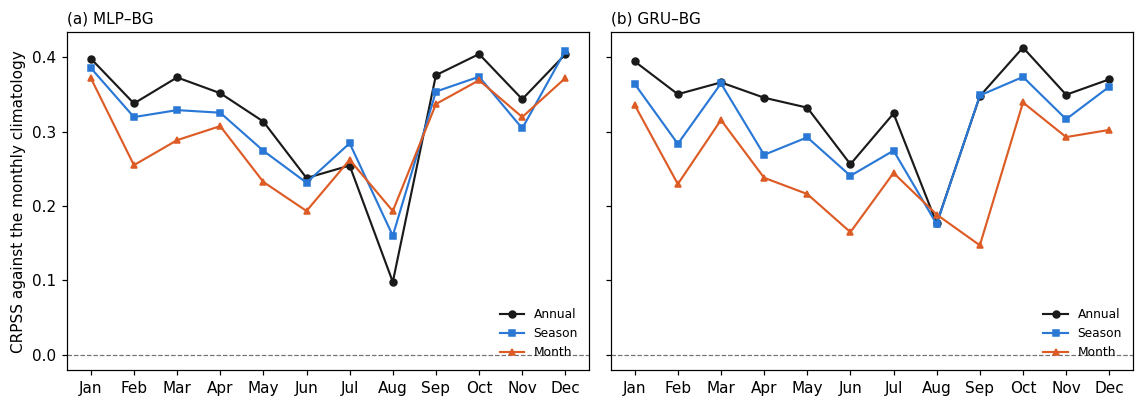

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
MLP_BG_Annual,0.40,0.34,0.37,0.35,0.31,0.24,0.25,0.10,0.38,0.40,0.34,0.40
MLP_BG_SeasonalConcat,0.39,0.32,0.33,0.33,0.27,0.23,0.28,0.16,0.35,0.37,0.30,0.41
MLP_BG_MonthConcat,0.37,0.25,0.29,0.31,0.23,0.19,0.26,0.19,0.34,0.37,0.32,0.37
GRU_BG_Annual,0.39,0.35,0.37,0.35,0.33,0.26,0.32,0.18,0.35,0.41,0.35,0.37
GRU_BG_SeasonalConcat,0.36,0.28,0.36,0.27,0.29,0.24,0.27,0.18,0.35,0.37,0.32,0.36
GRU_BG_MonthConcat,0.34,0.23,0.32,0.24,0.22,0.16,0.24,0.19,0.15,0.34,0.29,0.30


In [14]:
month_labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
test_months = test_dates.month.to_numpy()
monthly = pd.DataFrame({model_name: [1 - crps[test_months == m].mean() / crps_climatology[test_months == m].mean() for m in range(1, 13)]
                        for model_name, crps in daily_crps.items()}, index=month_labels)

scale_styles = {"Annual": ("Annual", "#1a1a1a", "o"), "SeasonalConcat": ("Season", "#2a78d6", "s"), "MonthConcat": ("Month", "#dd5b25", "^")}
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8), dpi=110, sharey=True)
for ax, architecture, title in zip(axes, CFG.architectures, ("(a) MLP–BG", "(b) GRU–BG")):
    ax.axhline(0, color="0.45", ls="--", lw=0.8)
    for time_scale, (label, color, marker) in scale_styles.items():
        ax.plot(range(1, 13), monthly[f"{architecture}_{time_scale}"], marker=marker, color=color, lw=1.4, ms=4.5, label=label)
    ax.set(xticks=range(1, 13), xticklabels=month_labels)
    ax.set_title(title, loc="left", fontsize=10)
    ax.legend(frameon=False, fontsize=8, loc="lower right")
axes[0].set_ylabel("CRPSS against the monthly climatology")
fig.tight_layout()
plt.show()
monthly.T.round(2)

**Figure 2.** Monthly CRPS skill score of (a) MLP–BG and (b) GRU–BG against the monthly climatology, at the three training scales. The dashed line marks the skill of the climatology.

## 8. References

- Cannon, A. J. (2008). Probabilistic multisite precipitation downscaling by an expanded Bernoulli–gamma density
  network. *Journal of Hydrometeorology*, 9(6), 1284–1300. https://doi.org/10.1175/2008JHM960.1
- Cho, K., van Merriënboer, B., Gulcehre, C., Bahdanau, D., Bougares, F., Schwenk, H. and Bengio, Y. (2014). Learning
  phrase representations using RNN encoder–decoder for statistical machine translation. *Proceedings of the 2014
  Conference on Empirical Methods in Natural Language Processing*, 1724–1734. https://doi.org/10.3115/v1/D14-1179
- Ferro, C. A. T. (2014). Fair scores for ensemble forecasts. *Quarterly Journal of the Royal Meteorological Society*, 140.
- Gneiting, T. and Raftery, A. E. (2007). Strictly proper scoring rules, prediction, and estimation. *Journal of the
  American Statistical Association*, 102, 359–378. https://doi.org/10.1198/016214506000001437
- Hersbach, H. et al. (2020). The ERA5 global reanalysis. *Quarterly Journal of the Royal Meteorological Society*, 146,
  1999–2049. https://doi.org/10.1002/qj.3803
- Klein Tank, A. M. G. et al. (2002). Daily dataset of 20th-century surface air temperature and precipitation series
  for the European Climate Assessment. *International Journal of Climatology*, 22, 1441–1453.
  https://doi.org/10.1002/joc.773
- Loshchilov, I. and Hutter, F. (2019). Decoupled weight decay regularization. *International Conference on Learning
  Representations*.